# 01 · Explore the flight data

**Goal of the project:** predict whether a U.S. domestic flight will arrive 15 or more minutes late, using only what is known before departure.

**This notebook** takes a first look at the cleaned data (September 2025 – August 2026) before any modeling:

1. How many flights are late?
2. How do the training, validation and test periods compare?
3. How does the late rate change by month, airline, and hour of day?
4. What causes the delay minutes?

The data comes from the U.S. Bureau of Transportation Statistics (BTS). `src/load.py` cleaned it and saved it as one Parquet file. Cancelled and diverted flights are left out here, because they have no arrival delay.

## 1. Load the data

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

# Find the project folder, so this works from VS Code or the command line.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "load.py").exists())
sys.path.insert(0, str(ROOT / "src"))

from load import load_flights
import plotstyle as ps

ps.apply_style()
flights = load_flights()
print(f"{len(flights):,} completed flights, {flights.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
print(f"From {flights['flight_date'].min():%b %d, %Y} to {flights['flight_date'].max():%b %d, %Y}")
flights.head()

6,895,984 completed flights, 386 MB in memory
From Sep 01, 2025 to Aug 31, 2026


,flight_date,carrier,tail_number,flight_number,origin,destination,scheduled_departure_hhmm,scheduled_arrival_hhmm,scheduled_elapsed_minutes,distance_miles,arrived_late,arrival_delay_minutes,departure_delay_minutes,carrier_delay_minutes,weather_delay_minutes,nas_delay_minutes,security_delay_minutes,late_aircraft_delay_minutes
0,2025-09-01,UA,N77592,1162,BQN,EWR,15,411,236.0,1585,0,-9.0,16.0,NaN,NaN,NaN,NaN,NaN
1,2025-09-01,AS,N530AS,168,FAI,SEA,18,500,222.0,1533,0,-43.0,-16.0,NaN,NaN,NaN,NaN,NaN
2,2025-09-01,F9,N307FR,1734,DEN,MCO,19,600,221.0,1547,0,-28.0,-4.0,NaN,NaN,NaN,NaN,NaN
3,2025-09-01,AA,N820NN,1148,PHX,ORD,24,601,217.0,1440,0,-22.0,-5.0,NaN,NaN,NaN,NaN,NaN
4,2025-09-01,DL,N304DU,368,FAI,SLC,30,715,285.0,2183,0,-17.0,-5.0,NaN,NaN,NaN,NaN,NaN


## 2. How many flights are late?

`arrived_late` is what we want to predict: 1 means the flight arrived 15 or more minutes late.

In [2]:
late_rate = flights["arrived_late"].mean()
print(f"Late (15+ minutes): {late_rate:.1%}")
print(f"On time:            {1 - late_rate:.1%}")

Late (15+ minutes): 22.7%
On time:            77.3%


Most flights are on time. That is why **accuracy is a misleading score** for this project: a "model" that always says *on time* would be right about 77% of the time while catching zero late flights. We will judge models with ROC-AUC and PR-AUC instead.

## 3. The date split

The model must be tested on flights that happen *after* the ones it learned from, the same way it would be used in real life. So we split by date, never randomly:

- **Train:** September 2025 – May 2026
- **Validate:** June 2026 (for tuning)
- **Test:** July – August 2026 (touched only at the end)

In [3]:
flights["split"] = "train"
flights.loc[flights["flight_date"] >= "2026-06-01", "split"] = "validate"
flights.loc[flights["flight_date"] >= "2026-07-01", "split"] = "test"

split_summary = (
    flights.groupby("split")["arrived_late"].agg(flights="size", late_rate="mean")
    .loc[["train", "validate", "test"]]
)
split_summary["share_of_flights_%"] = (100 * split_summary["flights"] / len(flights)).round(1)
split_summary["late_%"] = (100 * split_summary.pop("late_rate")).round(1)
split_summary

,flights,share_of_flights_%,late_%
split,,,
train,5094544,73.9,21.2
validate,595195,8.6,25.7
test,1206245,17.5,27.6


## 4. Late rate by month

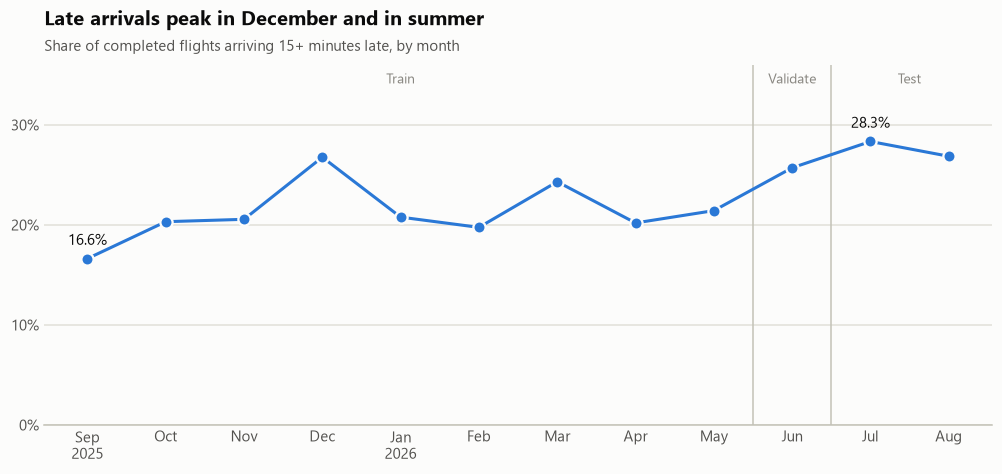

In [4]:
by_month = flights.groupby(flights["flight_date"].dt.to_period("M"))["arrived_late"].mean().mul(100)
x = list(range(len(by_month)))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, by_month.values, color=ps.BLUE, marker="o", markersize=8,
        markeredgecolor=ps.SURFACE, markeredgewidth=1.5, zorder=3)
ax.set_xticks(x, [p.strftime("%b\n%Y") if p.month in (9, 1) else p.strftime("%b") for p in by_month.index])
ax.set_ylim(0, 36)
ax.set_yticks(range(0, 36, 10))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

# Label only the best and worst months.
for i in (int(by_month.values.argmin()), int(by_month.values.argmax())):
    ax.annotate(f"{by_month.values[i]:.1f}%", (i, by_month.values[i]), xytext=(0, 9),
                textcoords="offset points", ha="center", color=ps.INK)

# Mark the train / validate / test periods.
n_train = int((by_month.index < "2026-06").sum())
for boundary in (n_train - 0.5, n_train + 0.5):
    ax.axvline(boundary, color=ps.AXIS, linewidth=1, zorder=1)
for center, label in [((n_train - 1) / 2, "Train"), (n_train, "Validate"), (n_train + 1.5, "Test")]:
    ax.text(center, 34.5, label, ha="center", va="center", color=ps.MUTED, fontsize=9)

ps.title(ax, "Late arrivals peak in December and in summer",
         "Share of completed flights arriving 15+ minutes late, by month")
ps.save(fig, "late_rate_by_month")
plt.show()

## 5. Late rate by airline

BTS lists each flight under the airline that actually flew it. So **Delta** here means Delta's own (mainline) flights. Regional partners such as SkyWest and Republic are listed separately, and they fly for several big airlines at once.

In [5]:
AIRLINE_NAMES = {
    "AA": "American", "AS": "Alaska", "B6": "JetBlue", "DL": "Delta", "F9": "Frontier",
    "G4": "Allegiant", "HA": "Hawaiian", "MQ": "Envoy", "NK": "Spirit", "OH": "PSA",
    "OO": "SkyWest", "UA": "United", "WN": "Southwest", "YX": "Republic",
}

month = flights["flight_date"].dt.to_period("M")
by_airline = flights.groupby("carrier", observed=True).agg(
    flights=("arrived_late", "size"),
    late_pct=("arrived_late", lambda s: 100 * s.mean()),
)
first_month = month.groupby(flights["carrier"], observed=True).min()
last_month = month.groupby(flights["carrier"], observed=True).max()
months_seen = month.groupby(flights["carrier"], observed=True).nunique()

by_airline["airline"] = [
    AIRLINE_NAMES.get(code, code)
    + ("" if months_seen[code] == 12 else f" ({first_month[code]:%b}–{last_month[code]:%b} only)")
    for code in by_airline.index
]
by_airline = by_airline.sort_values("late_pct")
by_airline[["airline", "flights", "late_pct"]].round(1)

,airline,flights,late_pct
carrier,,,
DL,Delta,1018714,18.9
MQ,Envoy,312533,19.0
HA,Hawaiian (Sep–Dec only),25915,19.2
AS,Alaska,305255,20.3
UA,United,819606,21.2
OO,SkyWest,837359,21.3
YX,Republic,346970,21.9
WN,Southwest,1375352,24.3
AA,American,964225,25.3


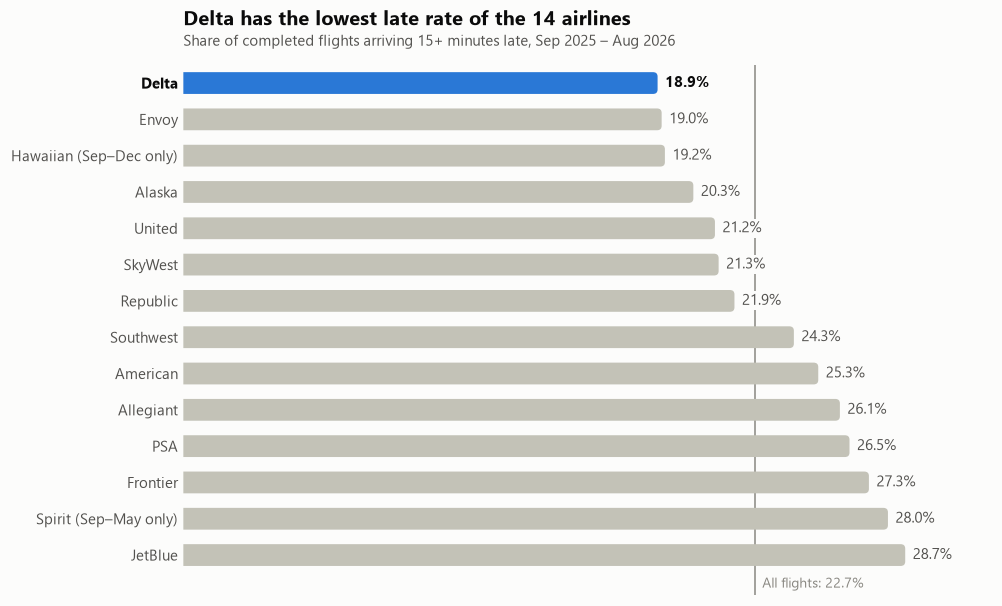

In [6]:
positions = list(range(len(by_airline)))
colors = [ps.BLUE if code == "DL" else ps.AXIS for code in by_airline.index]

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.set_xlim(0, by_airline["late_pct"].max() * 1.12)
ax.set_ylim(len(by_airline) - 0.5, -0.5)          # best airline at the top
ax.set_yticks(positions, by_airline["airline"])
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
for label, code in zip(ax.get_yticklabels(), by_airline.index):
    if code == "DL":
        label.set_fontweight("bold")
        label.set_color(ps.INK)

ps.title(ax, "Delta has the lowest late rate of the 14 airlines",
         "Share of completed flights arriving 15+ minutes late, Sep 2025 – Aug 2026")
ps.barh_rounded(ax, positions, by_airline["late_pct"].tolist(), colors)

for pos, (code, value) in zip(positions, by_airline["late_pct"].items()):
    ax.text(value + 0.3, pos, f"{value:.1f}%", va="center", ha="left", zorder=3,
            color=ps.INK if code == "DL" else ps.INK_2,
            fontweight="bold" if code == "DL" else "normal",
            bbox=dict(facecolor=ps.SURFACE, edgecolor="none", pad=1.5))

# Reference line: the average over all flights.
average = 100 * flights["arrived_late"].mean()
ax.axvline(average, color=ps.MUTED, linewidth=1, zorder=1)
ax.text(average + 0.3, len(by_airline) - 0.2, f"All flights: {average:.1f}%", ha="left", va="center",
        color=ps.MUTED, fontsize=9)
ax.set_ylim(len(by_airline) + 0.1, -0.5)

ps.save(fig, "late_rate_by_airline")
plt.show()

## 6. Late rate by hour of day

Delays build up during the day: a plane that runs late in the morning is often still late on its later flights. This is the reason for the aircraft-rotation features in the next notebook.

Hours with very few flights (the middle of the night) are left out, because their rates jump around.

In [7]:
flights["hour"] = flights["scheduled_departure_hhmm"] // 100
hour_counts = flights.groupby("hour").size()
busy_hours = hour_counts[hour_counts >= 20_000].index

is_busy = flights["hour"].isin(busy_hours)
is_delta = flights["carrier"] == "DL"
by_hour = pd.DataFrame({
    "all_flights": flights[is_busy].groupby("hour")["arrived_late"].mean().mul(100),
    "delta": flights[is_busy & is_delta].groupby("hour")["arrived_late"].mean().mul(100),
    "flights": hour_counts[busy_hours],
})
by_hour.round(1)

,all_flights,delta,flights
hour,,,
5,8.3,7.5,187397
6,9.9,8.8,473146
7,12.6,11.9,514556
8,14.5,13.1,479164
9,16.4,14.0,392961
10,18.2,14.9,440536
11,20.1,17.4,426689
12,22.2,18.1,415805
13,23.8,19.0,413741


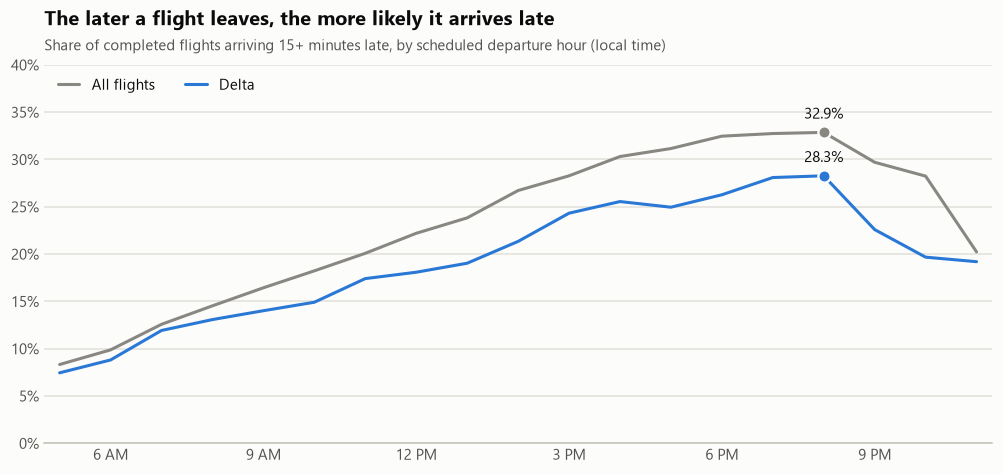

In [8]:
def hour_label(hour: int) -> str:
    return f"{(hour - 1) % 12 + 1} {'AM' if hour < 12 else 'PM'}"

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(by_hour.index, by_hour["all_flights"], color=ps.MUTED, label="All flights", zorder=2)
ax.plot(by_hour.index, by_hour["delta"], color=ps.BLUE, label="Delta", zorder=3)

ax.set_xlim(by_hour.index[0] - 0.3, by_hour.index[-1] + 0.3)
ax.set_xticks([h for h in by_hour.index if h % 3 == 0], [hour_label(h) for h in by_hour.index if h % 3 == 0])
ax.set_ylim(0, 40)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

# Label only the peak of each line.
for column, color in [("all_flights", ps.MUTED), ("delta", ps.BLUE)]:
    peak_hour, peak = by_hour[column].idxmax(), by_hour[column].max()
    ax.plot(peak_hour, peak, marker="o", markersize=8, color=color,
            markeredgecolor=ps.SURFACE, markeredgewidth=1.5, zorder=4)
    ax.annotate(f"{peak:.1f}%", (peak_hour, peak), xytext=(0, 9), textcoords="offset points",
                ha="center", color=ps.INK)

ax.legend(loc="upper left", ncols=2, handlelength=1.4)
ps.title(ax, "The later a flight leaves, the more likely it arrives late",
         "Share of completed flights arriving 15+ minutes late, by scheduled departure hour (local time)")
ps.save(fig, "late_rate_by_hour")
plt.show()

## 7. Day of week and hour together

Each square is one day-and-hour combination. Darker means a larger share of late flights.

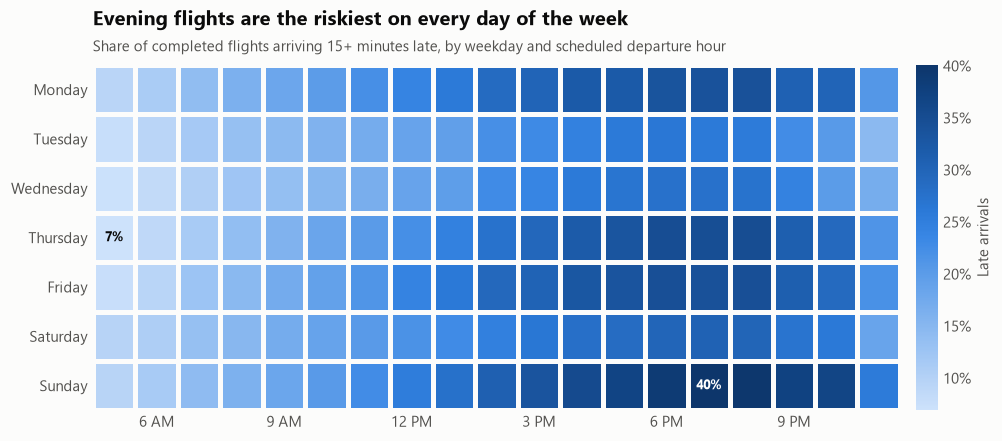

Worst: Sunday 7 PM, 40.1% late
Best:  Thursday 5 AM, 6.9% late


In [9]:
DAY_NAMES = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
flights["weekday"] = flights["flight_date"].dt.day_of_week

grid = (
    flights[is_busy].groupby(["weekday", "hour"])["arrived_late"].mean().mul(100).unstack("hour")
)

fig, ax = plt.subplots(figsize=(9, 3.9))
mesh = ax.pcolormesh(grid.values, cmap=ps.BLUES, edgecolors=ps.SURFACE, linewidth=2)
ax.set_ylim(7, 0)
ax.set_yticks([i + 0.5 for i in range(7)], DAY_NAMES)
ax.set_xticks([i + 0.5 for i, h in enumerate(grid.columns) if h % 3 == 0],
              [hour_label(h) for h in grid.columns if h % 3 == 0])
ax.grid(False)
ax.spines["bottom"].set_visible(False)

# Label only the worst and best squares.
worst = grid.stack().idxmax()
best = grid.stack().idxmin()
for (day, hour), text_color in [(worst, "#ffffff"), (best, ps.INK)]:
    ax.text(list(grid.columns).index(hour) + 0.5, day + 0.5, f"{grid.loc[day, hour]:.0f}%",
            ha="center", va="center", color=text_color, fontsize=8.5, fontweight="bold")

bar = fig.colorbar(mesh, ax=ax, pad=0.02, aspect=16, format=PercentFormatter(decimals=0))
bar.outline.set_visible(False)
bar.ax.tick_params(length=0)
bar.set_label("Late arrivals")

ps.title(ax, "Evening flights are the riskiest on every day of the week",
         "Share of completed flights arriving 15+ minutes late, by weekday and scheduled departure hour")
ps.save(fig, "late_rate_by_weekday_hour")
plt.show()

print(f"Worst: {DAY_NAMES[worst[0]]} {hour_label(worst[1])}, {grid.loc[worst]:.1f}% late")
print(f"Best:  {DAY_NAMES[best[0]]} {hour_label(best[1])}, {grid.loc[best]:.1f}% late")

## 8. What causes the delay minutes?

For flights that arrive 15+ minutes late, airlines report how many minutes each cause added. These columns are known only *after* the flight, so they can never be model inputs. They are useful for understanding the problem.

- **Late-arriving aircraft:** the plane's previous flight was late.
- **Airline's own operations:** crew, maintenance, baggage, fueling, boarding.
- **Air traffic system (NAS):** congestion, air traffic control, non-extreme weather.

In [10]:
CAUSES = {
    "late_aircraft_delay_minutes": "Late-arriving aircraft",
    "carrier_delay_minutes": "Airline's own operations",
    "nas_delay_minutes": "Air traffic system (NAS)",
    "weather_delay_minutes": "Extreme weather",
    "security_delay_minutes": "Security",
}

def cause_shares(frame: pd.DataFrame) -> pd.Series:
    minutes = frame[list(CAUSES)].astype("float64").sum()
    return (100 * minutes / minutes.sum()).rename(CAUSES)

causes = pd.DataFrame({
    "all_flights_%": cause_shares(flights),
    "delta_%": cause_shares(flights[is_delta]),
}).sort_values("all_flights_%", ascending=False)
causes.round(1)

,all_flights_%,delta_%
Late-arriving aircraft,39.9,29.4
Airline's own operations,32.9,44.1
Air traffic system (NAS),21.1,22.3
Extreme weather,6.0,4.1
Security,0.1,0.1


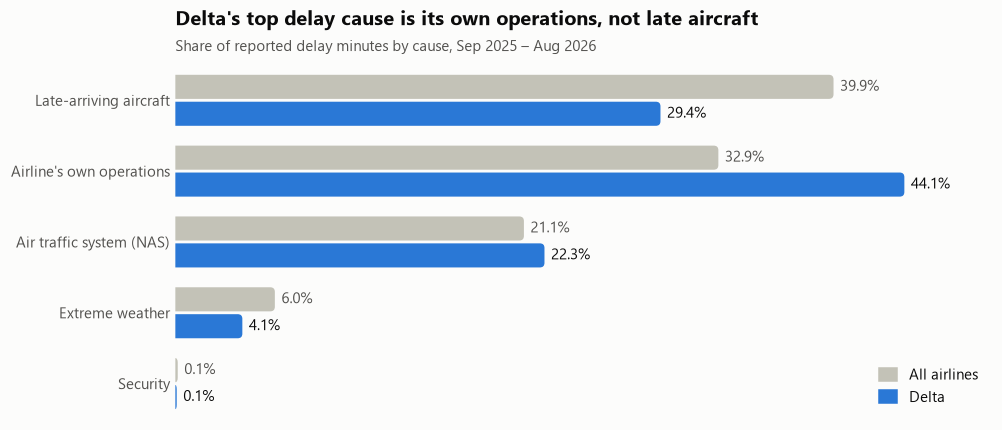

In [11]:
from matplotlib.patches import Patch

positions = list(range(len(causes)))
offset, height = 0.19, 0.34

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.set_xlim(0, causes.max().max() * 1.12)
ax.set_ylim(len(causes) - 0.5, -0.5)
ax.set_yticks(positions, causes.index)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)

ps.title(ax, "Delta's top delay cause is its own operations, not late aircraft",
         "Share of reported delay minutes by cause, Sep 2025 – Aug 2026")
ps.barh_rounded(ax, [p - offset for p in positions], causes["all_flights_%"].tolist(), ps.AXIS, height=height)
ps.barh_rounded(ax, [p + offset for p in positions], causes["delta_%"].tolist(), ps.BLUE, height=height)
for pos, (all_value, delta_value) in zip(positions, causes.itertuples(index=False)):
    ax.text(all_value + 0.4, pos - offset, f"{all_value:.1f}%", va="center", ha="left", color=ps.INK_2)
    ax.text(delta_value + 0.4, pos + offset, f"{delta_value:.1f}%", va="center", ha="left", color=ps.INK)

ax.legend(handles=[Patch(color=ps.AXIS, label="All airlines"), Patch(color=ps.BLUE, label="Delta")],
          loc="lower right", handlelength=1.2, handleheight=0.9)

ps.save(fig, "delay_causes")
plt.show()

## What we learned

1. **About 1 in 4 flights is late (22.7%).** Accuracy would flatter any model, so we use ROC-AUC and PR-AUC.
2. **The test months are harder than the training months.** 27.6% of test flights are late, compared with 21.2% in training. Summer is the busy season. Expect test scores a little below validation scores, and expect the model to underestimate how many flights are late in summer.
3. **Month matters.** September 2025 was the best month (16.6% late). December (26.8%) and July (28.3%) were the worst.
4. **Airline matters.** Delta has the lowest late rate (18.9%), and JetBlue the highest (28.7%).
5. **Hour of day is the strongest simple pattern.** The late rate climbs from 8.3% for 5 AM departures to 32.9% at 8 PM. Delta is below the average at every hour.
6. **Sunday evening is the worst time to fly** (40.1% late at 7 PM). Tuesday, Wednesday and Saturday are calmer.
7. **Late-arriving aircraft cause the most delay minutes overall (39.9%).** That matches the October class project (39.7%). For Delta the picture is different: its own operations cause 44.1% of its delay minutes, and late aircraft 29.4%.

## What this means for the model

- Scheduled hour, weekday, month and airline are all useful inputs, and all are known before departure.
- Delays spread from one flight to the next on the same aircraft. Notebook 02 builds **aircraft-rotation features** from the tail number and the schedule: which leg of the day this is, and how much turnaround time the plane has.
- Notebook 02 also adds the **FAA aircraft registry** (aircraft type and age).

Charts from this notebook are saved in `reports/figures/`.